# 02 · 建模和评估

结果由 `scripts/train_models.py` 生成并写入 `results/`，这里读取结果、比较并解释。

**怎么读这些数字**

- **选模型只看交叉验证**：按发动机分 5 折，同一台发动机不会同时出现在训练和验证里。主要指标是 `cv_rmse_near_failure`，只统计真实 RUL ≤ 125 的周期。
- **所有指标都和未截顶的真实 RUL 比较**，截顶只影响训练标签。
- **官方测试集只用来报告**。模型参数是事先定好的，没有根据测试集调整。
- `cv_score_per_100` 是每 100 个预测的官方分数；`test_score` 是 100 台测试发动机的官方分数总和。两者计算的样本范围不同，只能大致对照。

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rul.data import add_rul, engine_folds, load_rul, load_trajectories
from rul.evaluate import cross_validate, predict_rul
from rul.experiments import RESULTS_DIR, best_experiment, fit_final, prepare_table
from rul.metrics import nasa_score, rmse
from rul.models import SEED, build_model

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#c9c8c2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": GRAY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
pd.set_option("display.width", 200, "display.max_columns", 20)

summary = pd.read_csv(RESULTS_DIR / "summary.csv", keep_default_na=False)
summary["label"] = summary["model"] + " · " + summary["features"] + " · cap " + summary["cap"].astype(str)
summary.drop(columns="label")

,model,features,cap,cv_rmse_near_failure,cv_rmse_near_failure_std,cv_rmse_all_cycles,cv_score_per_100,test_rmse,test_score
0,lightgbm,window,125,14.04,0.82,47.25,394.04,14.57,308.68
1,lightgbm,window_all_columns,125,14.11,0.84,47.32,400.19,14.73,314.13
2,random_forest,window,125,14.44,0.98,48.34,435.17,14.44,311.42
3,lightgbm,window_no_core_speed,125,15.19,1.38,47.68,471.87,15.29,400.65
4,linear_regression,window,125,19.39,1.48,50.68,857.80,18.58,624.80
5,random_forest,raw,125,20.47,1.80,50.80,1995.55,17.96,809.05
6,lightgbm,raw,125,20.76,1.91,50.51,2140.71,18.08,957.28
7,linear_regression,raw,125,21.18,1.73,51.76,1183.57,21.90,1313.99
8,lightgbm,window,none,24.98,3.00,37.32,76337.61,27.02,6624.57
9,random_forest,window,none,25.05,2.92,37.41,69412.68,26.17,5276.29


## 1. 模型对比

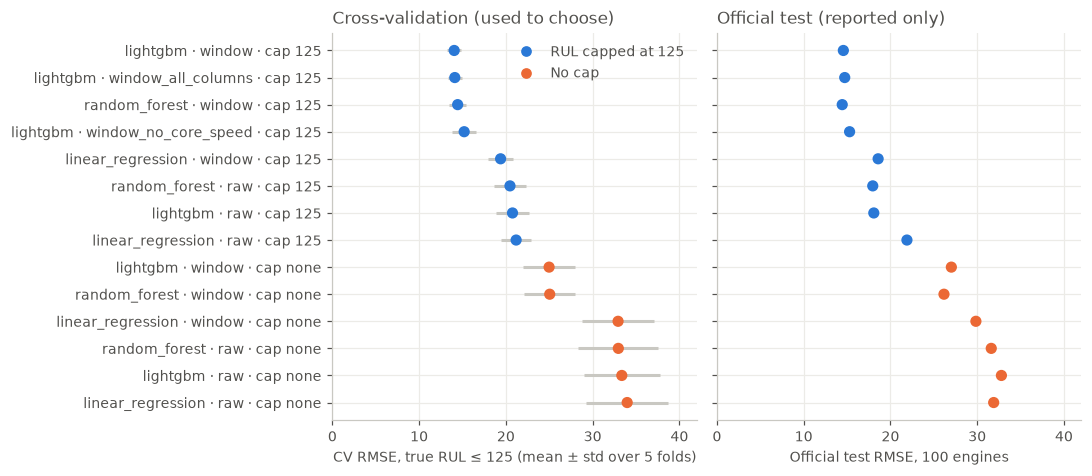

In [2]:
ordered = summary.iloc[::-1]
colors = [BLUE if cap != "none" else ORANGE for cap in ordered["cap"]]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True, gridspec_kw={"width_ratios": [1, 1]})
left.errorbar(ordered["cv_rmse_near_failure"], ordered["label"], xerr=ordered["cv_rmse_near_failure_std"],
              fmt="none", ecolor=GRAY, elinewidth=2, zorder=1)
left.scatter(ordered["cv_rmse_near_failure"], ordered["label"], c=colors, s=40, zorder=2)
left.set_xlabel("CV RMSE, true RUL ≤ 125 (mean ± std over 5 folds)")
left.set_title("Cross-validation (used to choose)", loc="left")
right.scatter(ordered["test_rmse"], ordered["label"], c=colors, s=40)
right.set_xlabel("Official test RMSE, 100 engines")
right.set_title("Official test (reported only)", loc="left")
for ax in (left, right):
    ax.set_xlim(0, 42)
left.legend(handles=[
    plt.Line2D([], [], marker="o", linestyle="", color=BLUE, label="RUL capped at 125"),
    plt.Line2D([], [], marker="o", linestyle="", color=ORANGE, label="No cap"),
], frameon=False, loc="upper right")
plt.tight_layout()

## 2. 差异是真的，还是噪声？

每个实验用的是**相同的 5 折**，所以可以逐折配对比较：看差值的均值，以及 5 折里有几折方向一致。折数只有 5，这不是严格的显著性检验，只是判断差异是否稳定。

In [3]:
def fold_rmse(name):
    result = json.loads((RESULTS_DIR / f"{name}.json").read_text(encoding="utf-8"))
    return pd.DataFrame(result["cv_folds"]).set_index("fold")["rmse_near_failure"]


COMPARISONS = {
    "cap 125 vs no cap (LightGBM, window)": ("lightgbm__window__cap_125", "lightgbm__window__cap_none"),
    "window vs raw (LightGBM, cap)": ("lightgbm__window__cap_125", "lightgbm__raw__cap_125"),
    "window vs raw (linear, cap)": ("linear_regression__window__cap_125", "linear_regression__raw__cap_125"),
    "LightGBM vs linear (window, cap)": ("lightgbm__window__cap_125", "linear_regression__window__cap_125"),
    "LightGBM vs linear (raw, cap)": ("lightgbm__raw__cap_125", "linear_regression__raw__cap_125"),
    "LightGBM vs random forest (window, cap)": ("lightgbm__window__cap_125", "random_forest__window__cap_125"),
    "keep Nc, NRc vs drop them": ("lightgbm__window__cap_125", "lightgbm__window_no_core_speed__cap_125"),
    "curated columns vs all columns": ("lightgbm__window__cap_125", "lightgbm__window_all_columns__cap_125"),
}
rows = []
for label, (a, b) in COMPARISONS.items():
    difference = fold_rmse(a) - fold_rmse(b)
    rows.append({"comparison (A vs B)": label, "mean RMSE change A - B": difference.mean().round(2),
                 "folds where A is better": f"{(difference < 0).sum()}/5"})
pd.DataFrame(rows)

,comparison (A vs B),mean RMSE change A - B,folds where A is better
0,"cap 125 vs no cap (LightGBM, window)",-10.94,5/5
1,"window vs raw (LightGBM, cap)",-6.72,5/5
2,"window vs raw (linear, cap)",-1.79,5/5
3,"LightGBM vs linear (window, cap)",-5.35,5/5
4,"LightGBM vs linear (raw, cap)",-0.42,2/5
5,"LightGBM vs random forest (window, cap)",-0.40,5/5
6,"keep Nc, NRc vs drop them",-1.16,5/5
7,curated columns vs all columns,-0.07,3/5


模型本身也有随机性（LightGBM 的行、列抽样）。这里固定折的划分，只换模型种子重跑，看单纯因为种子不同，指标会波动多少。差异如果比这个波动还小，就不能算真实差异。

In [4]:
table, feature_columns = prepare_table(load_trajectories("FD001", "train"), "window")
seed_runs = pd.Series({
    seed: cross_validate(lambda: build_model("lightgbm", seed), table, feature_columns, 125)["rmse_near_failure"].mean()
    for seed in [1, 2, 3, 4, 5]
}, name="CV RMSE")
print(seed_runs.round(2).to_string())
print(f"范围 {seed_runs.max() - seed_runs.min():.2f}，标准差 {seed_runs.std():.2f}")

1    14.06
2    14.04
3    14.03
4    14.11
5    14.05
范围 0.07，标准差 0.03


**发现**：只换种子时，CV RMSE 的波动只有 0.03（标准差）。

- **截顶是最大的提升**：LightGBM + 窗口特征从 24.98 降到 14.04，差 10.94，5 折都更好。
- **窗口特征第二**：LightGBM 降低 6.72；线性回归只降低 1.79。两者都是 5 折全胜。
- **模型差异要看特征**：只用单点读数时，LightGBM 和线性回归几乎没差别（-0.42，只有 2/5 折更好）；有了窗口特征后差距才拉开（-5.35，5/5）。单点噪声是共同的瓶颈，噪声降下来后，非线性模型才有发挥空间。第一个 notebook 也看到退化是加速的，这种弯曲的关系线性模型拟合不了。
- **LightGBM 和随机森林基本打平**：CV 差 0.40，虽然超过种子波动、5 折都更好，但官方测试集上随机森林反而略好（14.44 对 14.57）。这个差距没有实际意义，不能说 LightGBM 明显更强。
- **01_eda 留下的两个问题**：
  - **保留 Nc、NRc 更好**：去掉后 CV 变差 1.16，5/5 折一致。虽然方向因发动机而异，它们仍然有信息，和 01_eda 的假设一致。
  - **人工去掉 `sensor_6` 和 settings 基本没有影响**：差 0.07，只有 3/5 折更好。保留筛选是因为特征更少、更好解释，不是因为分数提高。

**指标之间的取舍**：不截顶模型的全周期 RMSE 反而更低（37.32 对 47.25），因为截顶模型不会预测超过 125 的值。如果业务要预测健康阶段的绝对寿命，结论可能不同；本项目关心临近故障阶段的维修决策，所以用 RUL ≤ 125 的指标选模型。这个指标本身对截顶模型有利，官方测试集（包含 RUL > 125 的发动机）也支持同样的结论：14.57 对 27.02。

**官方分数比 RMSE 更不稳定**：单点读数的树模型 CV 分数（约 2000）比线性回归（1184）差，但官方测试集上正好相反（809、957 对 1314）。指数惩罚让分数被少数大误差主导，少量样本就能改变排名，所以选模型时以 RMSE 为主、分数为辅。

## 3. 最终模型在官方测试集上的表现

`best_experiment()` 按交叉验证自动选出模型，然后用全部 100 台训练发动机重新拟合。

In [5]:
experiment = best_experiment()
print("选中的实验:", experiment.name)

train = load_trajectories("FD001", "train")
test = load_trajectories("FD001", "test")
true_rul = load_rul("FD001")

model = fit_final(experiment, train)
test_table, columns = prepare_table(test, experiment.features)
last = test_table.sort_values("cycle").groupby("unit").tail(1).sort_values("unit")
outcome = pd.DataFrame({
    "true": true_rul.loc[last["unit"]].to_numpy(),
    "predicted": predict_rul(model, last[columns]),
}, index=last["unit"])
outcome["error"] = outcome["predicted"] - outcome["true"]

print(f"测试集 RMSE {rmse(outcome['true'], outcome['predicted']):.2f}，官方分数 {nasa_score(outcome['true'], outcome['predicted']):.1f}")
print(f"平均误差 {outcome['error'].mean():+.2f}；报晚（高估寿命）{(outcome['error'] > 0).sum()} 台，报早 {(outcome['error'] < 0).sum()} 台")
print(f"最大低估 {outcome['error'].min():.1f}；最大高估 {outcome['error'].max():.1f}；|误差| > 30 的有 {(outcome['error'].abs() > 30).sum()} 台")
print(f"真实 RUL 范围 {outcome['true'].min()}–{outcome['true'].max()}；大于 125 的有 {(outcome['true'] > 125).sum()} 台")

bands = pd.cut(outcome["true"], [-1, 30, 60, 125, 500], labels=["≤30", "31–60", "61–125", ">125"])
by_band = outcome.groupby(bands, observed=True).apply(lambda g: pd.Series({
    "engines": len(g), "RMSE": rmse(g["true"], g["predicted"]), "mean error": g["error"].mean(),
}), include_groups=False).round(2)
by_band

选中的实验: lightgbm__window__cap_125


测试集 RMSE 14.57，官方分数 308.7
平均误差 +1.75；报晚（高估寿命）63 台，报早 37 台
最大低估 -40.6；最大高估 33.9；|误差| > 30 的有 5 台
真实 RUL 范围 7–145；大于 125 的有 11 台


,engines,RMSE,mean error
true,,,
≤30,25.0,6.27,2.62
31–60,14.0,10.49,4.84
61–125,50.0,16.54,5.28
>125,11.0,21.38,-20.20


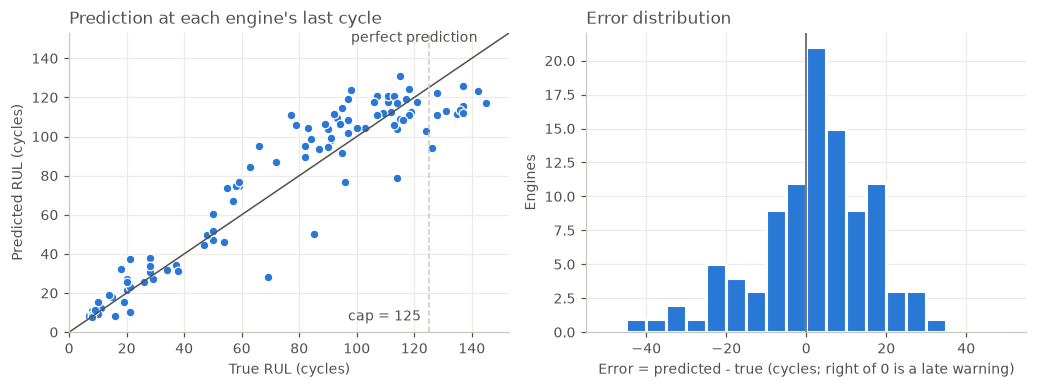

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9.5, 3.6))
limit = max(outcome["true"].max(), outcome["predicted"].max()) + 8
left.plot([0, limit], [0, limit], color=INK, linewidth=1)
left.axvline(125, color=GRAY, linewidth=1, linestyle="--")
left.scatter(outcome["true"], outcome["predicted"], color=BLUE, s=32, edgecolor="white", linewidth=0.8)
left.annotate("cap = 125", (125, 6), xytext=(-5, 0), textcoords="offset points", ha="right")
left.annotate("perfect prediction", (limit * 0.97, limit * 0.97), xytext=(-12, 0), textcoords="offset points", ha="right")
left.set(xlim=(0, limit), ylim=(0, limit), xlabel="True RUL (cycles)", ylabel="Predicted RUL (cycles)")
left.set_title("Prediction at each engine's last cycle", loc="left")

right.hist(outcome["error"], bins=np.arange(-50, 51, 5), color=BLUE, edgecolor="white", linewidth=2)
right.axvline(0, color=INK, linewidth=1)
right.set(xlabel="Error = predicted - true (cycles; right of 0 is a late warning)", ylabel="Engines")
right.set_title("Error distribution", loc="left")
plt.tight_layout()

**发现**

- **CV 和测试集结果接近**（14.04 对 14.57），说明交叉验证能反映对未见发动机的表现，也说明按发动机切分后没有明显的泄漏迹象。
- **越接近故障越准**：真实 RUL ≤ 30 时 RMSE 只有 6.27，61–125 时是 16.54。这正是维修决策最需要的区间。
- **截顶的代价看得见**：真实 RUL > 125 的 11 台平均低估约 20 个周期（左图虚线右侧，预测都压在 125 附近）。这是报早，方向上偏安全，但确实是误差。
- **总体略微报晚**：平均误差 +1.75，100 台里 63 台报晚。模型用的是对称的平方损失，并没有针对“报晚罚得更重”的官方分数优化。

## 4. 预警线的效果

单看 RMSE 不够，实际要回答的问题是：在“预测 RUL ≤ 阈值就安排维修”这个规则下，发动机能提前多久收到预警？会不会预警得太早？

**阈值不能用官方测试集来定**，所以先用训练集的交叉验证外预测（out-of-fold，每台发动机的预测都来自没见过它的模型），看每台发动机**第一次**触发预警时的真实 RUL。

In [7]:
table, feature_columns = prepare_table(train, experiment.features)
labels = add_rul(table[["unit", "cycle"]], cap=experiment.cap)["rul"].to_numpy()
oof = add_rul(table[["unit", "cycle"]])
oof["predicted"] = np.nan
for train_idx, val_idx in engine_folds(table):
    fold_model = build_model(experiment.model, SEED)
    fold_model.fit(table[feature_columns].iloc[train_idx], labels[train_idx])
    oof.iloc[val_idx, oof.columns.get_loc("predicted")] = predict_rul(fold_model, table[feature_columns].iloc[val_idx])

rows = []
for threshold in [20, 30, 40, 50, 60]:
    first_alert = oof[oof["predicted"] <= threshold].groupby("unit")["rul"].max()
    rows.append({
        "alert when predicted ≤": threshold,
        "engines alerted": len(first_alert),
        "median RUL at first alert": first_alert.median(),
        "lowest RUL at first alert": first_alert.min(),
        "first alert with RUL < 10": int((first_alert < 10).sum()),
        "first alert with RUL > 100": int((first_alert > 100).sum()),
    })
pd.DataFrame(rows)

,alert when predicted ≤,engines alerted,median RUL at first alert,lowest RUL at first alert,first alert with RUL < 10,first alert with RUL > 100
0,20,100,20.0,8,1,0
1,30,100,29.0,16,0,0
2,40,100,41.0,26,0,0
3,50,100,51.0,30,0,0
4,60,100,59.0,38,0,1


再用官方测试集的最后一个周期**报告**这个规则的效果（不用它选阈值）。这里的“应该预警”定义为真实 RUL ≤ 30。

In [8]:
TRUE_DANGER = 30
danger = outcome["true"] <= TRUE_DANGER
rows = []
for threshold in [20, 30, 40, 50]:
    alert = outcome["predicted"] <= threshold
    rows.append({
        "alert when predicted ≤": threshold,
        "alerts": int(alert.sum()),
        "caught": int((alert & danger).sum()),
        "missed": int((~alert & danger).sum()),
        "false alarms": int((alert & ~danger).sum()),
    })
print("真实 RUL ≤", TRUE_DANGER, "的发动机:", int(danger.sum()), "台")
pd.DataFrame(rows)

真实 RUL ≤ 30 的发动机: 25 台


,alert when predicted ≤,alerts,caught,missed,false alarms
0,20,13,13,12,0
1,30,20,19,6,1
2,40,29,25,0,4
3,50,33,25,0,8


**发现**

- **训练集交叉验证外的结果**：阈值 40 时，100 台发动机第一次预警的真实 RUL 中位数是 41，最晚也还剩 26 个周期，没有一台早于 RUL 100 就预警。阈值 30 时最晚只剩 16 个周期，给维修安排留的时间明显更少。所以 **Streamlit 默认阈值取 40**，这个选择来自训练集，不是测试集。
- **官方测试集报告**：阈值 40 时 25 台危险发动机全部抓到，4 台误报；阈值 30 时漏掉 6 台。报晚的代价通常比报早高，所以宁可多 4 台提前检查。
- 这里的“误报”是真实 RUL 大于 30 但预测 ≤ 40，这些发动机其实已经接近需要维修的范围。实际阈值应由维修周期和停机成本决定，这里只说明方法，不是通用答案。

## 5. 模型靠什么预测？

LightGBM 按分裂增益（gain）统计特征重要性。这说明模型“用了什么”，不代表因果关系；相关性强的特征之间，重要性可能互相转移。

                      gain share %  features
window mean                   64.3        14
window slope                  21.4        14
single-cycle reading          11.1        14
window std                     3.3        14

Nc/NRc（sensor_9、sensor_14）相关特征的增益占比: 9.8%


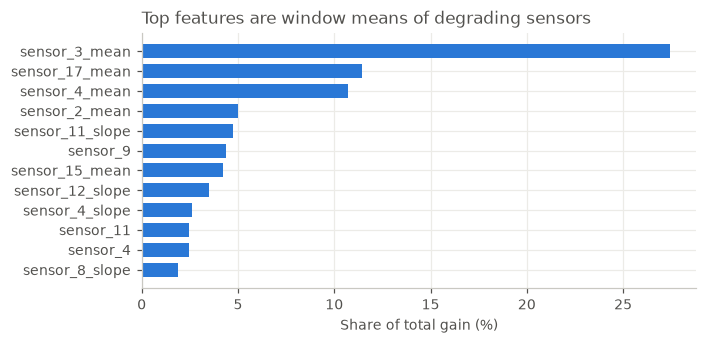

In [9]:
booster = model.named_steps["model"]
kept = np.array(columns)[model.named_steps["drop_constant"].get_support()]
importance = pd.Series(booster.booster_.feature_importance("gain"), index=kept).sort_values(ascending=False)
share = importance / importance.sum() * 100


def feature_kind(name):
    for suffix in ("mean", "std", "slope"):
        if name.endswith(suffix):
            return f"window {suffix}"
    return "single-cycle reading"


by_kind = share.groupby(share.index.map(feature_kind)).agg(["sum", "count"]).round(1)
by_kind.columns = ["gain share %", "features"]
print(by_kind.sort_values("gain share %", ascending=False).to_string())

top = share.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.set_xlabel("Share of total gain (%)")
ax.set_title("Top features are window means of degrading sensors", loc="left")
plt.tight_layout()
print()
print("Nc/NRc（sensor_9、sensor_14）相关特征的增益占比: "
      f"{share[share.index.str.match(r'sensor_(9|14)(_|$)')].sum():.1f}%")

**发现**

- **窗口特征贡献了约 89% 的增益**（均值 64.3%，斜率 21.4%，标准差 3.3%），单周期读数只有 11.1%。这和第 2 节窗口特征带来的提升一致。
- 增益最高的是 `sensor_3_mean`（T30，HPC 出口温度）。FD001 的故障模式是 HPC 退化，这个结果说得通，但特征重要性不能证明因果。
- Nc、NRc 相关特征合计占 9.8% 的增益，和“去掉后变差”的对照结果一致。

## 6. 结论

| 问题 | 答案 | 证据 |
|---|---|---|
| 哪个模型最好？ | **LightGBM + 窗口特征 + 截顶 125**（按 CV 规则选出），和随机森林基本打平 | CV 14.04 ± 0.82；测试 RMSE 14.57、分数 308.7；随机森林 CV 14.44、测试 14.44 |
| 比基线好多少？ | 测试 RMSE 从 21.90 降到 14.57，官方分数从 1314 降到 309 | 线性回归 + 单点读数 + 截顶 |
| 提升来自哪里？ | 影响从大到小：截顶标签、窗口特征、非线性模型 | 配对比较：-10.94、-6.72、-5.35 |
| 为什么？ | RUL 高时信号比噪声弱，截顶避免模型去拟合噪声；窗口平均降低单点噪声并提供趋势；退化是加速的，树模型能拟合这种非线性 | 01_eda 第 7 节；第 5 节特征重要性 |

**局限**

- 没有做超参数搜索。这是有意的取舍：先把防泄漏和验证流程做对，所以这些分数不是这些模型的上限。
- 窗口长度 30 没有比较其他取值，只保证了测试集最短轨迹也能凑满。
- 损失函数是对称的，没有针对官方分数的不对称性优化。
- 只有 FD001：一种工况、一种故障模式，而且是仿真数据。结果不能直接外推到其他子集或真实矿卡。